# Magic window — export window selection

Pick and preview **named export windows** on the full `margem_equatorial_tensor.zarr` grid.

Each **section** is self-contained: run **Setup** (cells 1–2) once, then for any section run its **settings & helpers** cell before the window cells in that section.

Related: `Magic_window_visualize.ipynb` · `01_export_magic_window.ipynb`

In [43]:
from pathlib import Path
import os
import sys

NOTEBOOK_DIR = Path.cwd().resolve()
MW_DIR = NOTEBOOK_DIR if NOTEBOOK_DIR.name == "Magic_window" else NOTEBOOK_DIR / "Magic_window"
ROOT = MW_DIR.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import zarr
from matplotlib.patches import Polygon, Rectangle

from src.data.useful_transforms import (
    FixedCrop,
    RotatedFixedCrop,
    rotated_window_corners,
)

PT_PATH = MW_DIR / "magic_window_lat_lon_bathymetry_wh(1).pt"
if not PT_PATH.exists():
    raise FileNotFoundError(f"Expected file at {PT_PATH}")

data = torch.load(PT_PATH, map_location="cpu", weights_only=False)
row_slice = tuple(data["row_slice"])
EXPORT_ROW_SLICE = row_slice
EXPORT_COL_SLICE = (85, 213)  # 128×128 export cols (matches 01_export_magic_window.ipynb)

print(f"Loaded: {PT_PATH.name}")
print(f"Magic row_slice={EXPORT_ROW_SLICE}, export col_slice={EXPORT_COL_SLICE}")


Loaded: magic_window_lat_lon_bathymetry_wh(1).pt
Magic row_slice=(226, 354), export col_slice=(85, 213)


In [44]:
def bathymetry_cmap(base="terrain_r"):
    cmap = plt.get_cmap(base).copy()
    cmap.set_bad(color="black")
    cmap.set_under(color="black")
    return cmap


def mask_bathymetry_land(field: np.ndarray) -> np.ma.MaskedArray:
    land = ~np.isfinite(field) | (field == 0)
    return np.ma.masked_where(land, field)


## Window catalog

Each section has its own **settings & helpers** cell (edit `ZARR_PATH`, `VIZ_TIME_IDX`, etc. per section).

| # | Export key | Display name | Section | Default geometry |
|---|------------|--------------|---------|------------------|
| 1 | `magicwin_reference` | Magic window (reference) | Effect of lands | 128×128 @ magic top-left (`.pt` anchor), 0° |
| 2 | `magicwin_high_land` | High land | Effect of lands | 128×128 @ (186, 85), 0° |
| 3 | `magicwin_open_ocean` | Open ocean (no land) | Effect of lands | 128×128 @ (300, 85), 0° |
| 4 | `magicwin_bathy_mid` | Bathymetry — mid domain | Bathymetry Effect | 128×128 @ (300, 245), 0° |
| 5 | `magicwin_bathy_east` | Bathymetry — east | Bathymetry Effect | 128×128 @ (300, 400), 0° |
| 6 | `magicwin_bathy_northeast` | Bathymetry — northeast | Bathymetry Effect | 128×128 @ (100, 350), 0° |
| 7 | `legacy_smallfixwin_0deg` | Legacy small (0°) | Rotation Effect | 128×128 @ anchor (250, 300), center pivot, 0° |
| 8b | `legacy_smallfixwin_68deg` | Legacy small (68°) | Rotation Effect | 128×128 @ anchor (250, 300), center pivot, 68° |
| 8a | `legacy_smallfixwin_23deg` | Legacy small (23°) | Rotation Effect | 128×128 @ anchor (250, 300), center pivot, 23° |
| 8 | `legacy_smallfixwin_45deg` | Legacy small (45°) | Rotation Effect | 128×128 @ anchor (250, 300), center pivot, 45° |
| 9 | `legacy_smallfixwin_90deg` | Legacy small (90°) | Rotation Effect | 128×128 @ anchor (250, 300), center pivot, 90° |
| 10 | `legacy_smallfixwin_135deg` | Legacy small (135°) | Rotation Effect | 128×128 @ anchor (250, 300), center pivot, 135° |
| 11 | `legacy_smallfixwin_180deg` | Legacy small (180°) | Rotation Effect | 128×128 @ anchor (250, 300), center pivot, 180° |
| 12 | `legacy_largefixwin` | Legacy large (−35°) | Size Effect | 128×384 @ center pivot (303.3, 262.2), −35° |
| 13 | `legacy_smallfixwin_in_large` | Small in large | Size Effect | 128×128 centered in legacy large, −35° |

**WINDOW dict fields:** `export_key`, `crop_height`, `crop_width`, `window_angle`, `rotation_pivot`, `window_top`/`window_left`, optional `pivot_col`/`pivot_row`.

Export data layout (see `01_export_magic_window.ipynb`):
```
data/{export_key}/
  sample_13_22_train_uv_dt360
  sample_13_22_val_uv_dt360
  sample_23_uv_dt360
  sample_13_22_split.json
```

## Magic-window family

Windows anchored on the magic `.pt` patch. **Run settings & helpers below first.**

Subsections:
- **Effect of lands** — `magicwin_reference`, `magicwin_high_land`, `magicwin_open_ocean`
- **Bathymetry Effect** — `magicwin_bathy_mid`, `magicwin_bathy_east`, `magicwin_bathy_northeast`

In [45]:
# === Magic-window family — settings & helpers ===
# Re-run this cell when you change section-specific settings below.
SECTION = "magic_window"

ZARR_PATH = os.getenv(
    "GUIANA_ZARR_PATH",
    "s3://oceangen-data/margem_equatorial_tensor.zarr",
)

VIZ_TIME_IDX = 0  # zarr time index for u/v snapshot

# Window outlines on full-domain plots (high contrast, like Size Effect section)
WINDOW_EDGE_COLORS = {
    "magicwin_reference": "#00E5FF",       # cyan — reference magic window
    "magicwin_high_land": "#FF6600",       # orange — high land
    "magicwin_open_ocean": "#76FF03",       # green — open ocean
    "magicwin_bathy_mid": "#E040FB",        # purple — bathy mid
    "magicwin_bathy_east": "#FFD600",       # yellow — bathy east
    "magicwin_bathy_northeast": "#FF5252",  # red — bathy northeast
    "legacy_smallfixwin_0deg": "#00BCD4",   # teal — rotation 0°
    "legacy_smallfixwin_23deg": "#E91E63",  # pink — rotation 23°
    "legacy_smallfixwin_68deg": "#FF5722",  # deep orange — rotation 68°
    "legacy_smallfixwin_45deg": "#9C27B0",  # violet — rotation 45°
}
WINDOW_EDGE_WIDTH = 3

# Dashed magic-window reference on all full-domain panels (from .pt / export cols)
SHOW_MAGIC_REFERENCE = True
MAGIC_REF_COLOR = "#FF4444"
MAGIC_REF_LINEWIDTH = 2
MAGIC_REF_LINESTYLE = "--"

MAGIC_ANCHOR_TOP = int(EXPORT_ROW_SLICE[0])
MAGIC_ANCHOR_LEFT = int(EXPORT_COL_SLICE[0])
MAGIC_HEIGHT = int(EXPORT_ROW_SLICE[1] - EXPORT_ROW_SLICE[0])
MAGIC_WIDTH = int(EXPORT_COL_SLICE[1] - EXPORT_COL_SLICE[0])
MAGIC_CENTER_COL = MAGIC_ANCHOR_LEFT + (MAGIC_WIDTH - 1) / 2.0
MAGIC_CENTER_ROW = MAGIC_ANCHOR_TOP + (MAGIC_HEIGHT - 1) / 2.0
MAGIC_PIVOT_LEFT = MAGIC_ANCHOR_LEFT
MAGIC_PIVOT_BOTTOM_ROW = MAGIC_ANCHOR_TOP + MAGIC_HEIGHT - 1

print(
    f"Magic reference: top-left=({MAGIC_ANCHOR_TOP}, {MAGIC_ANCHOR_LEFT}), "
    f"center=({MAGIC_CENTER_COL:.1f}, {MAGIC_CENTER_ROW:.1f}), "
    f"size={MAGIC_HEIGHT}×{MAGIC_WIDTH}"
)


def top_left_from_center_pivot(
    pivot_col: float,
    pivot_row: float,
    height: int,
    width: int,
    angle_deg: float,
) -> tuple[int, int]:
    angle = np.deg2rad(float(angle_deg))
    sin_a, cos_a = float(np.sin(angle)), float(np.cos(angle))
    col_c = (int(width) - 1) / 2.0
    row_c = (int(height) - 1) / 2.0
    left = pivot_col - col_c * cos_a + row_c * sin_a
    top = pivot_row - col_c * sin_a - row_c * cos_a
    return int(round(top)), int(round(left))


def top_left_from_bottom_left_pivot(
    pivot_col: float,
    pivot_row: float,
    height: int,
    width: int,
    angle_deg: float,
) -> tuple[int, int]:
    angle = np.deg2rad(float(angle_deg))
    sin_a, cos_a = float(np.sin(angle)), float(np.cos(angle))
    h_span = max(int(height) - 1, 0)
    left = int(round(pivot_col + h_span * sin_a))
    top = int(round(pivot_row - h_span * cos_a))
    return top, left


def resolve_window(name: str, cfg: dict) -> dict:
    """Build export spec from editable WINDOW dict.

    cfg keys: crop_height, crop_width, window_angle, rotation_pivot,
              window_top, window_left, pivot_col, pivot_row (optional)
    rotation_pivot: "top_left" | "center" | "bottom_left"
    """
    h = int(cfg["crop_height"])
    w = int(cfg["crop_width"])
    ang = float(cfg["window_angle"])
    pivot_mode = str(cfg.get("rotation_pivot", "top_left"))

    pivot_col = cfg.get("pivot_col")
    pivot_row = cfg.get("pivot_row")
    win_top = cfg.get("window_top")
    win_left = cfg.get("window_left")

    if pivot_mode == "center":
        if pivot_col is None or pivot_row is None:
            if win_top is None or win_left is None:
                raise ValueError(f"{name}: center pivot needs pivot_col/pivot_row or window_top/window_left")
            pivot_col = float(win_left) + (w - 1) / 2.0
            pivot_row = float(win_top) + (h - 1) / 2.0
        top, left = top_left_from_center_pivot(float(pivot_col), float(pivot_row), h, w, ang)
    elif pivot_mode == "bottom_left":
        if pivot_col is None or pivot_row is None:
            if win_top is None or win_left is None:
                raise ValueError(f"{name}: bottom_left pivot needs pivot_col/pivot_row or window_top/window_left")
            pivot_col = float(win_left) + (h - 1) * np.sin(np.deg2rad(ang))
            pivot_row = float(win_top) + (h - 1) * np.cos(np.deg2rad(ang))
        top, left = top_left_from_bottom_left_pivot(float(pivot_col), float(pivot_row), h, w, ang)
    elif pivot_mode == "top_left":
        if win_top is None or win_left is None:
            raise ValueError(f"{name}: top_left pivot needs window_top and window_left")
        top, left = int(win_top), int(win_left)
        if pivot_col is None:
            pivot_col = left + (w - 1) / 2.0
        if pivot_row is None:
            pivot_row = top + (h - 1) / 2.0
    else:
        raise ValueError(f"Unknown rotation_pivot={pivot_mode!r}")

    center_col = left + (w - 1) / 2.0 * np.cos(np.deg2rad(ang)) - (h - 1) / 2.0 * np.sin(np.deg2rad(ang))
    center_row = top + (w - 1) / 2.0 * np.sin(np.deg2rad(ang)) + (h - 1) / 2.0 * np.cos(np.deg2rad(ang))

    export_key = str(cfg.get("export_key") or name)
    return {
        "name": name,
        "export_key": export_key,
        "crop_height": h,
        "crop_width": w,
        "window_top": int(top),
        "window_left": int(left),
        "window_angle": ang,
        "rotation_pivot": pivot_mode,
        "pivot_col": float(pivot_col) if pivot_col is not None else None,
        "pivot_row": float(pivot_row) if pivot_row is not None else None,
        "center_col": float(center_col),
        "center_row": float(center_row),
    }


def _extract_frame_channels(frame_arr, ch_names):
    arr = np.asarray(frame_arr)
    if arr.ndim == 5:
        arr = arr[0]
    if arr.ndim == 4 and arr.shape[0] == 1:
        arr = arr[0]
    idx = {n: i for i, n in enumerate(ch_names)}
    return {name: np.asarray(arr[idx[name]]) for name in ("bathymetry", "u", "v")}


def load_domain_fields(time_idx: int = VIZ_TIME_IDX):
    zgroup = zarr.open_group(ZARR_PATH, mode="r")
    ch_names = [c.decode() if isinstance(c, bytes) else str(c) for c in zgroup["channel"][:]]
    fields = _extract_frame_channels(zgroup["ocean_tensor"][int(time_idx)], ch_names)
    t_str = str(pd.to_datetime(zgroup["time"][int(time_idx)]))
    return fields, t_str, ch_names


def build_window_crop(crop_height, crop_width, window_top, window_left, window_angle):
    if float(window_angle) == 0.0:
        return FixedCrop(size=(crop_height, crop_width), top=window_top, left=window_left)
    return RotatedFixedCrop(
        size=(crop_height, crop_width),
        top=window_top,
        left=window_left,
        angle_deg=float(window_angle),
    )


def print_window_info(spec: dict):
    export_key = spec.get("export_key", spec["name"])
    rows = [
        ("export_key", export_key),
        ("data_dir", f"Magic_window/data/{export_key}"),
        ("train_prefix", f"Magic_window/data/{export_key}/sample_13_22_train_uv_dt360"),
        ("val_prefix", f"Magic_window/data/{export_key}/sample_13_22_val_uv_dt360"),
        ("test_prefix", f"Magic_window/data/{export_key}/sample_23_uv_dt360"),
        ("crop_height", spec["crop_height"]),
        ("crop_width", spec["crop_width"]),
        ("window_top", spec["window_top"]),
        ("window_left", spec["window_left"]),
        ("window_angle", spec["window_angle"]),
        ("rotation_pivot", spec["rotation_pivot"]),
        ("pivot_col", spec.get("pivot_col")),
        ("pivot_row", spec.get("pivot_row")),
        ("center_col", round(spec["center_col"], 2)),
        ("center_row", round(spec["center_row"], 2)),
        (
            "export_window.npy",
            f"[{spec['window_top']}, {spec['window_left']}, {spec['crop_height']}, "
            f"{spec['crop_width']}, {spec['window_angle']}]",
        ),
    ]
    info = pd.DataFrame(rows, columns=["field", "value"])
    try:
        display(info.style.hide(axis="index"))
    except Exception:
        print(info.to_string(index=False))
    print("Copy for export notebook:")
    for key in ("CROP_HEIGHT", "CROP_WIDTH", "WINDOW_TOP", "WINDOW_LEFT", "WINDOW_ANGLE"):
        field = key.replace("CROP_", "crop_").replace("WINDOW_", "window_").lower()
        val = spec[field]
        print(f"  {key} = {val!r}")
    print(f"For 01_export_magic_window.ipynb — use export_key={export_key!r} and coordinates above.")
    if export_key == "magicwin_reference":
        print('  WINDOW_MODE = "magic"  # matches .pt anchor')
        print(f"  # row_slice={EXPORT_ROW_SLICE}, export col_slice={EXPORT_COL_SLICE}")
    if spec["window_top"] < 0 or spec["window_left"] < 0:
        print("WARNING: window_top or window_left < 0 — RotatedFixedCrop will reject this geometry.")
    return spec


def _window_edge_style(spec: dict) -> tuple[str, float]:
    key = spec.get("export_key", "")
    color = WINDOW_EDGE_COLORS.get(key, "#FFEB3B")
    return color, WINDOW_EDGE_WIDTH


def _add_magic_reference_outline(ax, label="magic window (ref)"):
    """Dashed outline of axis-aligned magic export window on full-domain plots."""
    if not SHOW_MAGIC_REFERENCE:
        return
    ax.add_patch(
        Rectangle(
            (MAGIC_ANCHOR_LEFT, MAGIC_ANCHOR_TOP),
            MAGIC_WIDTH,
            MAGIC_HEIGHT,
            fill=False,
            edgecolor=MAGIC_REF_COLOR,
            linewidth=MAGIC_REF_LINEWIDTH,
            linestyle=MAGIC_REF_LINESTYLE,
            alpha=0.95,
            label=label,
        )
    )


def _add_window_outline(ax, spec, edgecolor=None, linewidth=None, label=None):
    if edgecolor is None or linewidth is None:
        default_color, default_width = _window_edge_style(spec)
        edgecolor = default_color if edgecolor is None else edgecolor
        linewidth = default_width if linewidth is None else linewidth
    if label is None:
        label = spec.get("export_key", spec.get("name"))
    top, left = spec["window_top"], spec["window_left"]
    h, w, ang = spec["crop_height"], spec["crop_width"], spec["window_angle"]
    if float(ang) == 0.0:
        ax.add_patch(
            Rectangle((left, top), w, h, fill=False, edgecolor=edgecolor, linewidth=linewidth, label=label)
        )
    else:
        corners = rotated_window_corners(top, left, h, ang, w)
        ax.add_patch(Polygon(corners, fill=False, edgecolor=edgecolor, linewidth=linewidth, label=label))
    pc, pr = spec.get("pivot_col"), spec.get("pivot_row")
    if spec["rotation_pivot"] == "center" and pc is not None and pr is not None:
        ax.plot(pc, pr, "r*", ms=12, label="pivot (center)")
    elif spec["rotation_pivot"] == "bottom_left" and pc is not None and pr is not None:
        ax.plot(pc, pr, "r*", ms=12, label="pivot (BL)")


def _percentile_vlim(field, lo=2, hi=98):
    valid = field[np.isfinite(field)]
    if valid.size == 0:
        return None, None
    return float(np.percentile(valid, lo)), float(np.percentile(valid, hi))


def visualize_window_on_domain(spec: dict, time_idx: int = VIZ_TIME_IDX, show_crops: bool = True):
    fields, t_str, _ = load_domain_fields(time_idx)
    bathy, u, v = fields["bathymetry"], fields["u"], fields["v"]
    b_valid = bathy[np.isfinite(bathy) & (bathy != 0)]
    b_vmin = float(b_valid.min()) if b_valid.size else None
    b_vmax = float(b_valid.max()) if b_valid.size else None
    u_vmin, u_vmax = _percentile_vlim(u)
    v_vmin, v_vmax = _percentile_vlim(v)

    nrows = 2 if show_crops else 1
    fig, axes = plt.subplots(nrows, 3, figsize=(18, 6 * nrows))
    if nrows == 1:
        axes = np.expand_dims(axes, 0)

    panels = [
        (bathy, "Bathymetry", bathymetry_cmap(), b_vmin, b_vmax),
        (u, "u", "RdBu_r", u_vmin, u_vmax),
        (v, "v", "RdBu_r", v_vmin, v_vmax),
    ]
    for ax, (field, label, cmap, vmin, vmax) in zip(axes[0], panels):
        masked = mask_bathymetry_land(field) if label == "Bathymetry" else field
        im = ax.imshow(masked, cmap=cmap, vmin=vmin, vmax=vmax, origin="upper")
        if SHOW_MAGIC_REFERENCE:
            _add_magic_reference_outline(ax, label="magic window (ref)")
        _add_window_outline(ax, spec, label=spec.get("export_key", "export window"))
        ax.set_title(f"Full domain — {label}")
        ax.set_xlabel("col")
        ax.set_ylabel("row")
        fig.colorbar(im, ax=ax, shrink=0.7)
    axes[0, 0].legend(loc="lower right", fontsize=7)

    if show_crops:
        stack = torch.tensor(np.stack([u, v, bathy], axis=0), dtype=torch.float32)
        crop = build_window_crop(spec["crop_height"], spec["crop_width"], spec["window_top"], spec["window_left"], spec["window_angle"])
        cropped = crop(stack).numpy()
        for ax, (field, title, cmap, vmin, vmax) in zip(
            axes[1],
            [
                (cropped[2], "Bathymetry (crop)", bathymetry_cmap(), b_vmin, b_vmax),
                (cropped[0], "u (crop)", "RdBu_r", u_vmin, u_vmax),
                (cropped[1], "v (crop)", "RdBu_r", v_vmin, v_vmax),
            ],
        ):
            masked = mask_bathymetry_land(field) if title.startswith("Bathymetry") else field
            im = ax.imshow(masked, cmap=cmap, vmin=vmin, vmax=vmax, origin="upper")
            ax.set_title(title)
            ax.set_xticks([])
            ax.set_yticks([])
            fig.colorbar(im, ax=ax, shrink=0.7)

    fig.suptitle(
        f"[{spec.get('export_key', spec['name'])}] {spec['crop_height']}×{spec['crop_width']} @ "
        f"top={spec['window_top']}, left={spec['window_left']}, angle={spec['window_angle']}° "
        f"(pivot={spec['rotation_pivot']}) | t={t_str}",
        fontsize=13,
    )
    plt.tight_layout()
    plt.show()



try:
    _probe, _t0, _ = load_domain_fields(VIZ_TIME_IDX)
    print(f"Loaded zarr fields @ time index {VIZ_TIME_IDX}: {_t0}")
    print(f"Grid shape (rows×cols): {_probe['bathymetry'].shape}")
except Exception as exc:
    print(f"Could not preload zarr (set GUIANA_ZARR_PATH): {exc}")

Magic reference: top-left=(226, 85), center=(148.5, 289.5), size=128×128
Loaded zarr fields @ time index 0: 2013-01-01 00:00:00
Grid shape (rows×cols): (431, 547)


### Effect of lands

Axis-aligned 128×128 magic windows at different positions to study **land coverage**.

Land is masked black on **bathymetry** plots; **u/v** show raw values.

On full-domain plots: **dashed red** = magic window from `.pt`; **solid colored** = export window from editable `WINDOW` dict.

field,value
export_key,magicwin_reference
data_prefix,Magic_window/data/sample_13_22_magicwin_reference_uv_dt360
crop_height,128
crop_width,128
window_top,226
window_left,85
window_angle,0.000000
rotation_pivot,top_left
pivot_col,148.500000
pivot_row,289.500000


Copy for export notebook:
  CROP_HEIGHT = 128
  CROP_WIDTH = 128
  WINDOW_TOP = 226
  WINDOW_LEFT = 85
  WINDOW_ANGLE = 0.0
For 01_export_magic_window.ipynb — use export_key='magicwin_reference' and coordinates above.
  WINDOW_MODE = "magic"  # matches .pt anchor
  # row_slice=(226, 354), export col_slice=(85, 213)


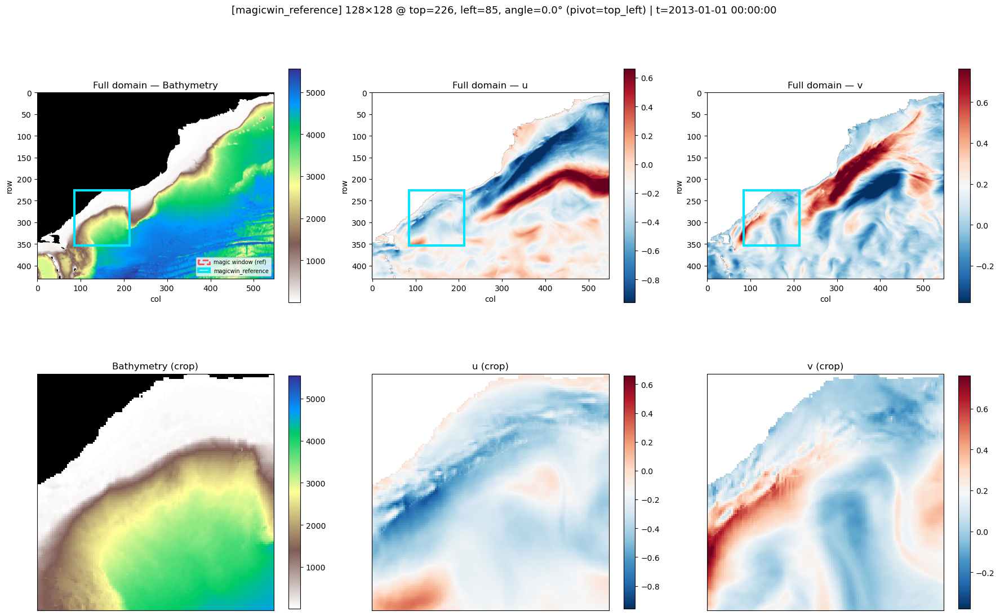

In [46]:
# magicwin_reference — Magic window (reference) @ .pt anchor
WINDOW = dict(
    export_key="magicwin_reference",
    crop_height=128,
    crop_width=128,
    window_top=MAGIC_ANCHOR_TOP,
    window_left=MAGIC_ANCHOR_LEFT,
    window_angle=0.0,
    rotation_pivot="top_left",
    pivot_col=None,
    pivot_row=None,
)

MAGIC_SPEC = resolve_window("Magic window (reference)", WINDOW)
print_window_info(MAGIC_SPEC)
_ = visualize_window_on_domain(MAGIC_SPEC)


field,value
export_key,magicwin_high_land
data_prefix,Magic_window/data/sample_13_22_magicwin_high_land_uv_dt360
crop_height,128
crop_width,128
window_top,186
window_left,85
window_angle,0.000000
rotation_pivot,top_left
pivot_col,148.500000
pivot_row,249.500000


Copy for export notebook:
  CROP_HEIGHT = 128
  CROP_WIDTH = 128
  WINDOW_TOP = 186
  WINDOW_LEFT = 85
  WINDOW_ANGLE = 0.0
For 01_export_magic_window.ipynb — use export_key='magicwin_high_land' and coordinates above.


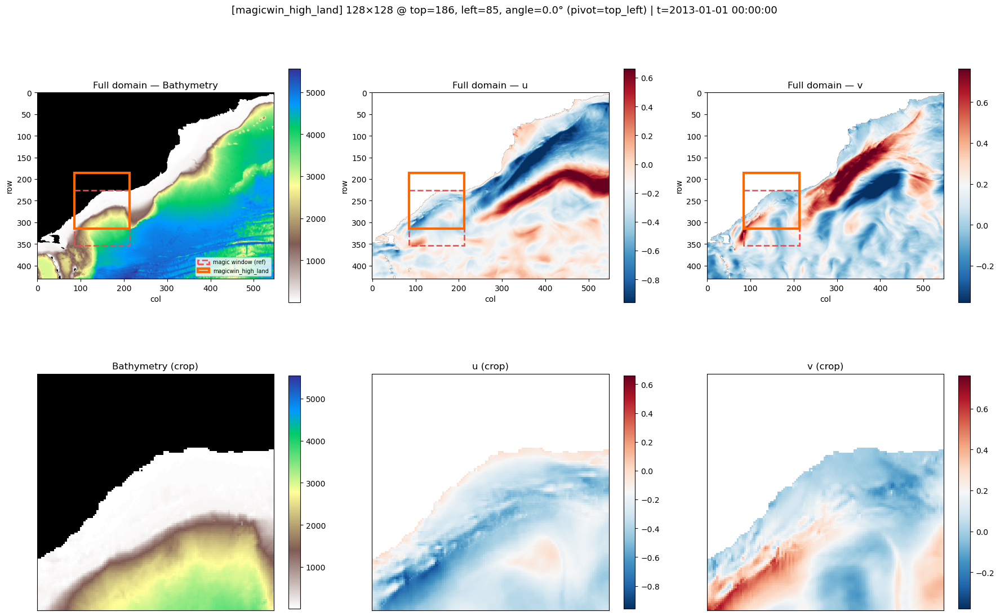

In [47]:
# magicwin_high_land — High land
WINDOW = dict(
    export_key="magicwin_high_land",
    crop_height=128,
    crop_width=128,
    window_top=186,
    window_left=85,
    window_angle=0.0,
    rotation_pivot="top_left",
    pivot_col=None,
    pivot_row=None,
)

MAGIC_SPEC = resolve_window("High land", WINDOW)
print_window_info(MAGIC_SPEC)
_ = visualize_window_on_domain(MAGIC_SPEC)


field,value
export_key,magicwin_open_ocean
data_prefix,Magic_window/data/sample_13_22_magicwin_open_ocean_uv_dt360
crop_height,128
crop_width,128
window_top,300
window_left,85
window_angle,0.000000
rotation_pivot,top_left
pivot_col,148.500000
pivot_row,363.500000


Copy for export notebook:
  CROP_HEIGHT = 128
  CROP_WIDTH = 128
  WINDOW_TOP = 300
  WINDOW_LEFT = 85
  WINDOW_ANGLE = 0.0
For 01_export_magic_window.ipynb — use export_key='magicwin_open_ocean' and coordinates above.


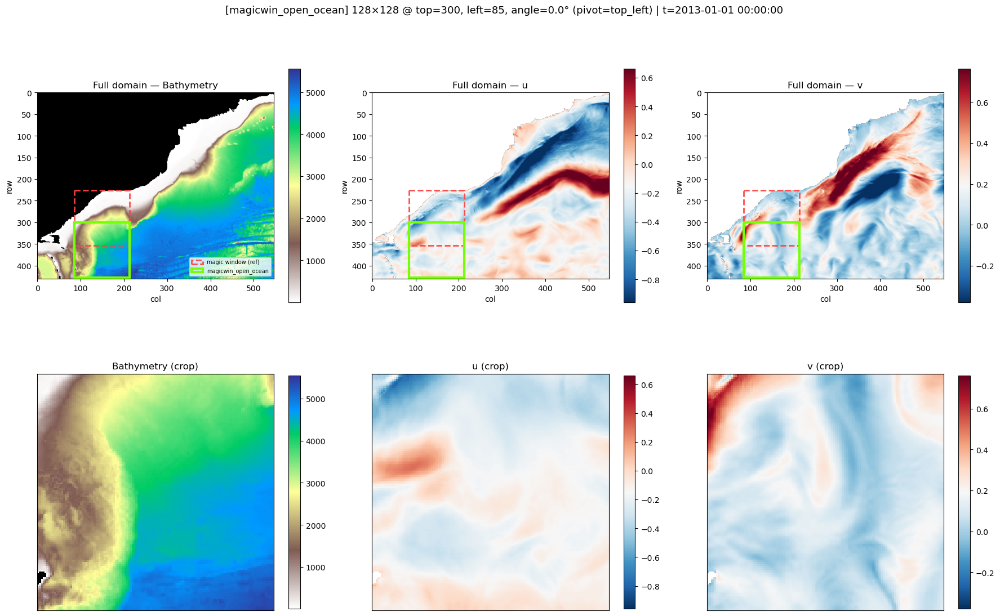

In [48]:
# magicwin_open_ocean — Open ocean (no land)
WINDOW = dict(
    export_key="magicwin_open_ocean",
    crop_height=128,
    crop_width=128,
    window_top=300,
    window_left=85,
    window_angle=0.0,
    rotation_pivot="top_left",
    pivot_col=None,
    pivot_row=None,
)

MAGIC_SPEC = resolve_window("Open ocean (no land)", WINDOW)
print_window_info(MAGIC_SPEC)
_ = visualize_window_on_domain(MAGIC_SPEC)


## Bathymetry Effect

Axis-aligned 128×128 magic windows at different positions to study **bathymetry** patterns.

field,value
export_key,magicwin_bathy_mid
data_prefix,Magic_window/data/sample_13_22_magicwin_bathy_mid_uv_dt360
crop_height,128
crop_width,128
window_top,300
window_left,245
window_angle,0.000000
rotation_pivot,top_left
pivot_col,308.500000
pivot_row,363.500000


Copy for export notebook:
  CROP_HEIGHT = 128
  CROP_WIDTH = 128
  WINDOW_TOP = 300
  WINDOW_LEFT = 245
  WINDOW_ANGLE = 0.0
For 01_export_magic_window.ipynb — use export_key='magicwin_bathy_mid' and coordinates above.


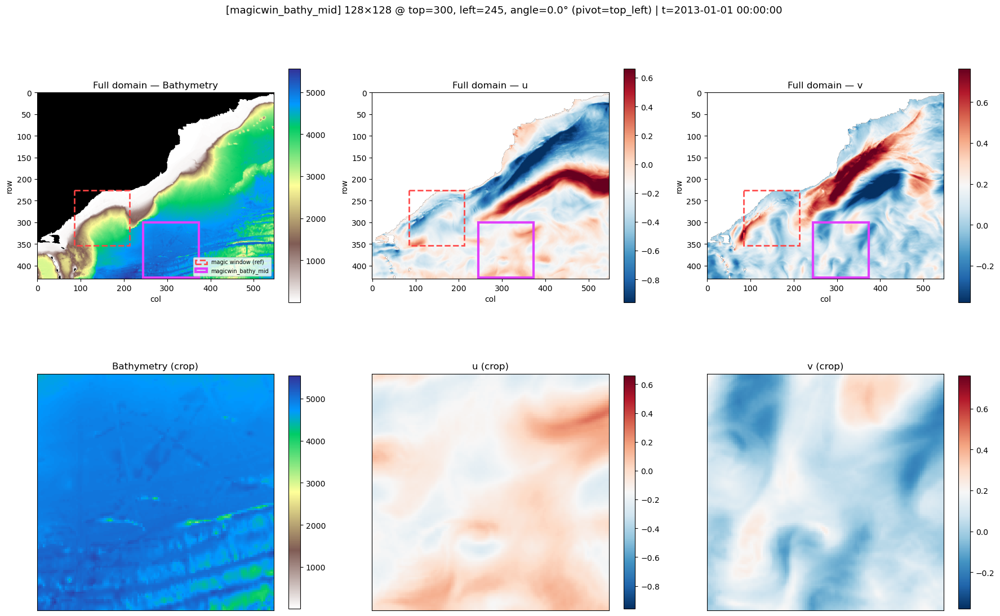

In [49]:
# magicwin_bathy_mid — Bathymetry — mid domain
WINDOW = dict(
    export_key="magicwin_bathy_mid",
    crop_height=128,
    crop_width=128,
    window_top=300,
    window_left=245,
    window_angle=0.0,
    rotation_pivot="top_left",
    pivot_col=None,
    pivot_row=None,
)

MAGIC_SPEC = resolve_window("Bathymetry — mid domain", WINDOW)
print_window_info(MAGIC_SPEC)
_ = visualize_window_on_domain(MAGIC_SPEC)


field,value
export_key,magicwin_bathy_east
data_prefix,Magic_window/data/sample_13_22_magicwin_bathy_east_uv_dt360
crop_height,128
crop_width,128
window_top,300
window_left,400
window_angle,0.000000
rotation_pivot,top_left
pivot_col,463.500000
pivot_row,363.500000


Copy for export notebook:
  CROP_HEIGHT = 128
  CROP_WIDTH = 128
  WINDOW_TOP = 300
  WINDOW_LEFT = 400
  WINDOW_ANGLE = 0.0
For 01_export_magic_window.ipynb — use export_key='magicwin_bathy_east' and coordinates above.


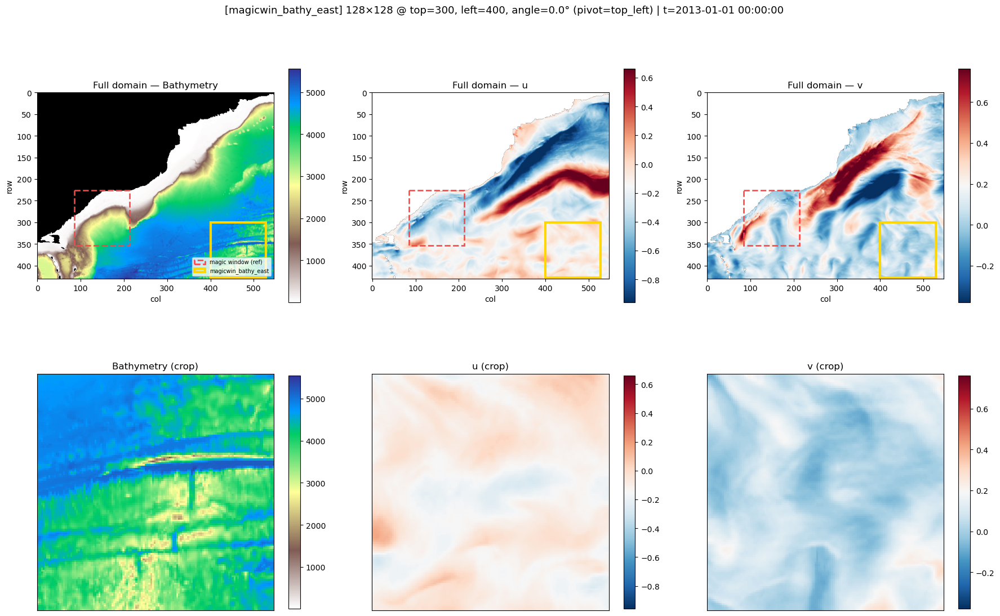

In [50]:
# magicwin_bathy_east — Bathymetry — east
WINDOW = dict(
    export_key="magicwin_bathy_east",
    crop_height=128,
    crop_width=128,
    window_top=300,
    window_left=400,
    window_angle=0.0,
    rotation_pivot="top_left",
    pivot_col=None,
    pivot_row=None,
)

MAGIC_SPEC = resolve_window("Bathymetry — east", WINDOW)
print_window_info(MAGIC_SPEC)
_ = visualize_window_on_domain(MAGIC_SPEC)


field,value
export_key,magicwin_bathy_northeast
data_prefix,Magic_window/data/sample_13_22_magicwin_bathy_northeast_uv_dt360
crop_height,128
crop_width,128
window_top,100
window_left,350
window_angle,0.000000
rotation_pivot,top_left
pivot_col,413.500000
pivot_row,163.500000


Copy for export notebook:
  CROP_HEIGHT = 128
  CROP_WIDTH = 128
  WINDOW_TOP = 100
  WINDOW_LEFT = 350
  WINDOW_ANGLE = 0.0


/tmp/ipykernel_1735351/3874829340.py:251: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0, 0].legend(loc="lower right", fontsize=7)


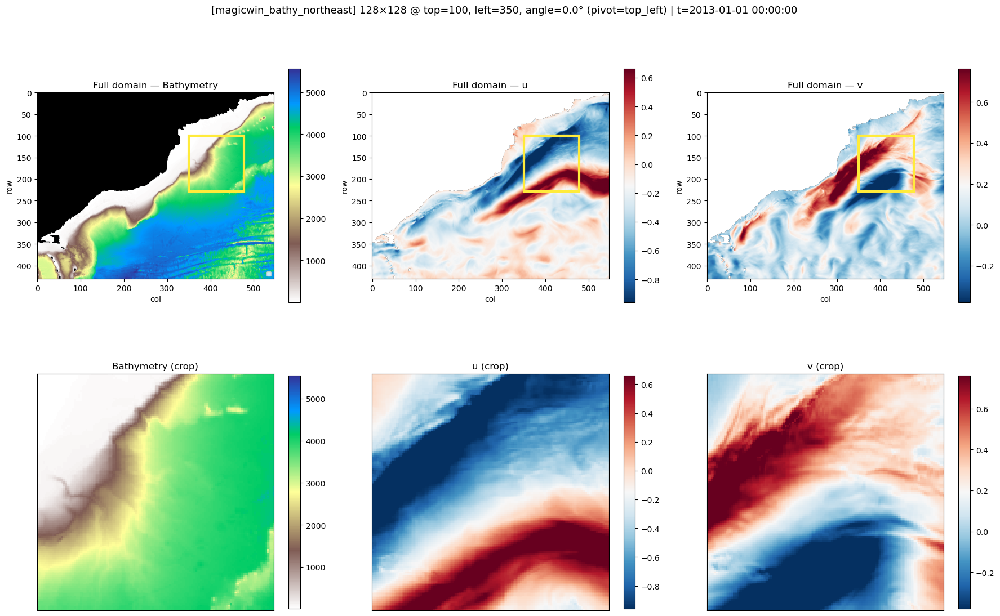

In [59]:
# magicwin_bathy_northeast — Bathymetry — northeast
WINDOW = dict(
    export_key="magicwin_bathy_northeast",
    crop_height=128,
    crop_width=128,
    window_top=100,
    window_left=350,
    window_angle=0.0,
    rotation_pivot="top_left",
    pivot_col=None,
    pivot_row=None,
)

MAGIC_SPEC = resolve_window("Bathymetry — northeast", WINDOW)
print_window_info(MAGIC_SPEC)
_ = visualize_window_on_domain(MAGIC_SPEC)


## Rotation Effect

Legacy 128×128 fix-window at the same anchor with different **rotation angles**.


field,value
export_key,legacy_smallfixwin_0deg
data_prefix,Magic_window/data/sample_13_22_legacy_smallfixwin_0deg_uv_dt360
crop_height,128
crop_width,128
window_top,250
window_left,300
window_angle,0.000000
rotation_pivot,center
pivot_col,363.500000
pivot_row,313.500000


Copy for export notebook:
  CROP_HEIGHT = 128
  CROP_WIDTH = 128
  WINDOW_TOP = 250
  WINDOW_LEFT = 300
  WINDOW_ANGLE = 0.0


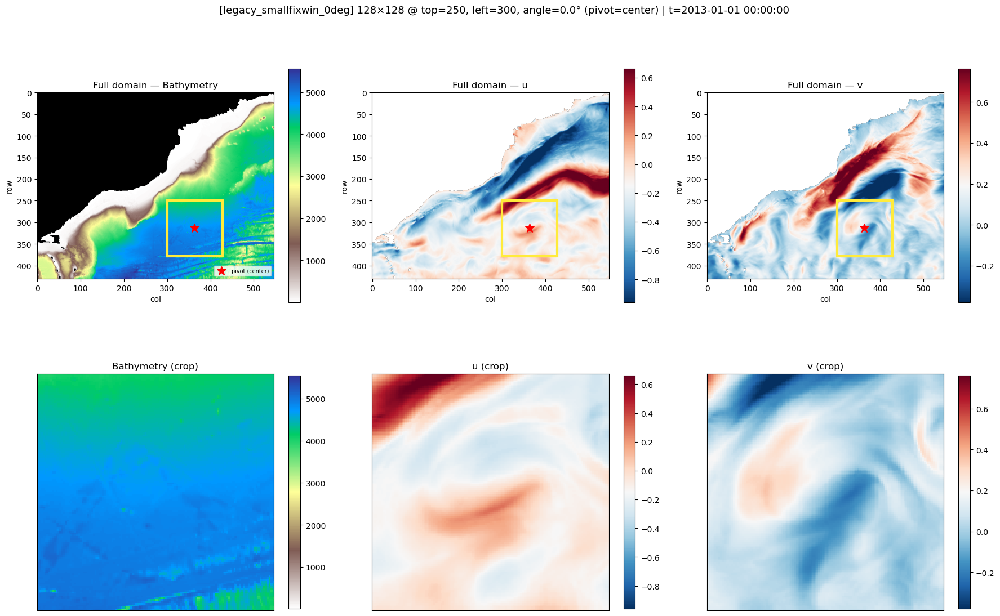

In [60]:
# legacy_smallfixwin_0deg — Legacy small (0°)
WINDOW = dict(
    export_key="legacy_smallfixwin_0deg",
    crop_height=128,
    crop_width=128,
    window_top=250,
    window_left=300,
    window_angle=0.0,
    rotation_pivot="center",
    pivot_col=None,
    pivot_row=None,
)

LEGACY_SMALL_SPEC = resolve_window("Legacy small (0°)", WINDOW)
print_window_info(LEGACY_SMALL_SPEC)
_ = visualize_window_on_domain(LEGACY_SMALL_SPEC)


field,value
export_key,legacy_smallfixwin_45deg
data_prefix,Magic_window/data/sample_13_22_legacy_smallfixwin_45deg_uv_dt360
crop_height,128
crop_width,128
window_top,224
window_left,364
window_angle,45.000000
rotation_pivot,center
pivot_col,363.500000
pivot_row,313.500000


Copy for export notebook:
  CROP_HEIGHT = 128
  CROP_WIDTH = 128
  WINDOW_TOP = 224
  WINDOW_LEFT = 364
  WINDOW_ANGLE = 45.0


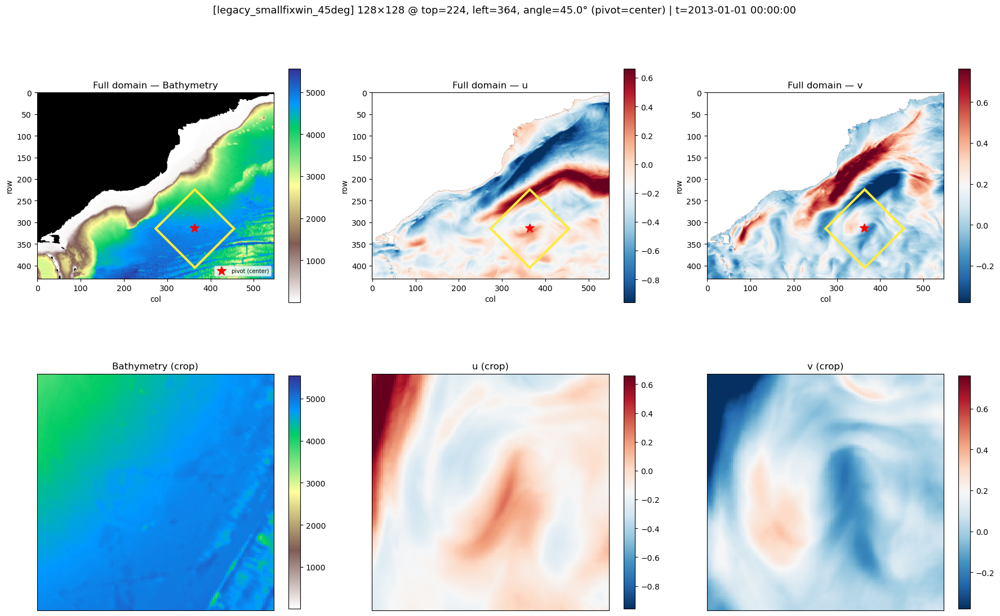

In [61]:
# legacy_smallfixwin_45deg — Legacy small (45°)
WINDOW = dict(
    export_key="legacy_smallfixwin_45deg",
    crop_height=128,
    crop_width=128,
    window_top=250,
    window_left=300,
    window_angle=45.0,
    rotation_pivot="center",
    pivot_col=None,
    pivot_row=None,
)

LEGACY_SMALL_SPEC = resolve_window("Legacy small (45°)", WINDOW)
print_window_info(LEGACY_SMALL_SPEC)
_ = visualize_window_on_domain(LEGACY_SMALL_SPEC)


In [ ]:
# legacy_smallfixwin_23deg — Legacy small (23°)
WINDOW = dict(
    export_key="legacy_smallfixwin_23deg",
    crop_height=128,
    crop_width=128,
    window_top=250,
    window_left=300,
    window_angle=23.0,
    rotation_pivot="center",
    pivot_col=None,
    pivot_row=None,
)

LEGACY_SMALL_SPEC = resolve_window("Legacy small (23°)", WINDOW)
print_window_info(LEGACY_SMALL_SPEC)
_ = visualize_window_on_domain(LEGACY_SMALL_SPEC)


In [ ]:
# legacy_smallfixwin_68deg — Legacy small (68°)
WINDOW = dict(
    export_key="legacy_smallfixwin_68deg",
    crop_height=128,
    crop_width=128,
    window_top=250,
    window_left=300,
    window_angle=68.0,
    rotation_pivot="center",
    pivot_col=None,
    pivot_row=None,
)

LEGACY_SMALL_SPEC = resolve_window("Legacy small (68°)", WINDOW)
print_window_info(LEGACY_SMALL_SPEC)
_ = visualize_window_on_domain(LEGACY_SMALL_SPEC)


field,value
export_key,legacy_smallfixwin_90deg
data_prefix,Magic_window/data/sample_13_22_legacy_smallfixwin_90deg_uv_dt360
crop_height,128
crop_width,128
window_top,250
window_left,427
window_angle,90.000000
rotation_pivot,center
pivot_col,363.500000
pivot_row,313.500000


Copy for export notebook:
  CROP_HEIGHT = 128
  CROP_WIDTH = 128
  WINDOW_TOP = 250
  WINDOW_LEFT = 427
  WINDOW_ANGLE = 90.0


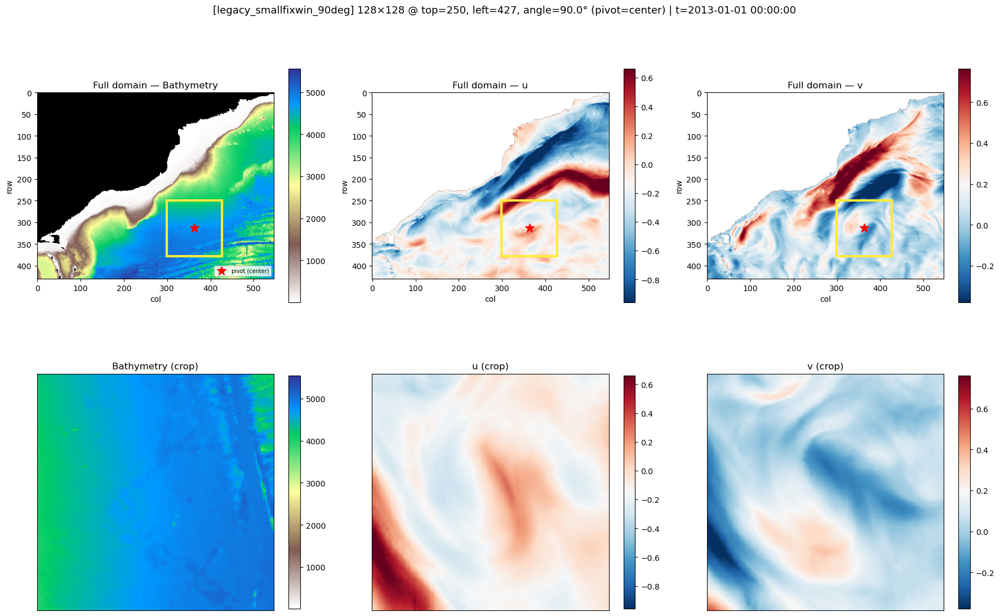

In [62]:
# legacy_smallfixwin_45deg — Legacy small (90°)
WINDOW = dict(
    export_key="legacy_smallfixwin_90deg",
    crop_height=128,
    crop_width=128,
    window_top=250,
    window_left=300,
    window_angle=90.0,
    rotation_pivot="center",
    pivot_col=None,
    pivot_row=None,
)

LEGACY_SMALL_SPEC = resolve_window("Legacy small (90°)", WINDOW)
print_window_info(LEGACY_SMALL_SPEC)
_ = visualize_window_on_domain(LEGACY_SMALL_SPEC)


field,value
export_key,legacy_smallfixwin_135deg
data_prefix,Magic_window/data/sample_13_22_legacy_smallfixwin_135deg_uv_dt360
crop_height,128
crop_width,128
window_top,314
window_left,453
window_angle,135.000000
rotation_pivot,center
pivot_col,363.500000
pivot_row,313.500000


Copy for export notebook:
  CROP_HEIGHT = 128
  CROP_WIDTH = 128
  WINDOW_TOP = 314
  WINDOW_LEFT = 453
  WINDOW_ANGLE = 135.0


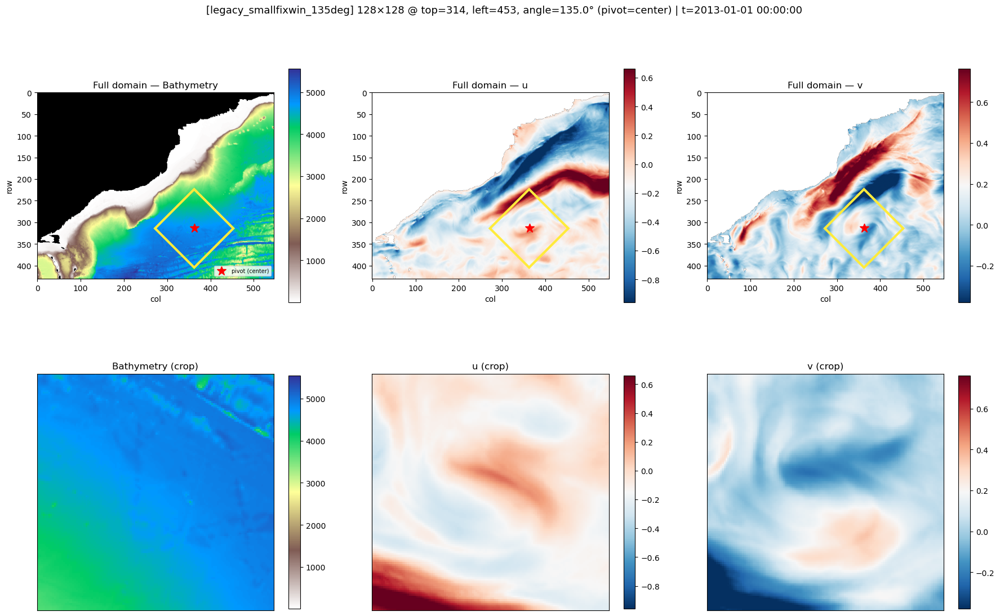

In [66]:
# legacy_smallfixwin_45deg — Legacy small (135°)
WINDOW = dict(
    export_key="legacy_smallfixwin_135deg",
    crop_height=128,
    crop_width=128,
    window_top=250,
    window_left=300,
    window_angle=135.0,
    rotation_pivot="center",
    pivot_col=None,
    pivot_row=None,
)

LEGACY_SMALL_SPEC = resolve_window("Legacy small (135°)", WINDOW)
print_window_info(LEGACY_SMALL_SPEC)
_ = visualize_window_on_domain(LEGACY_SMALL_SPEC)


field,value
export_key,legacy_smallfixwin_180deg
data_prefix,Magic_window/data/sample_13_22_legacy_smallfixwin_180deg_uv_dt360
crop_height,128
crop_width,128
window_top,377
window_left,427
window_angle,180.000000
rotation_pivot,center
pivot_col,363.500000
pivot_row,313.500000


Copy for export notebook:
  CROP_HEIGHT = 128
  CROP_WIDTH = 128
  WINDOW_TOP = 377
  WINDOW_LEFT = 427
  WINDOW_ANGLE = 180.0


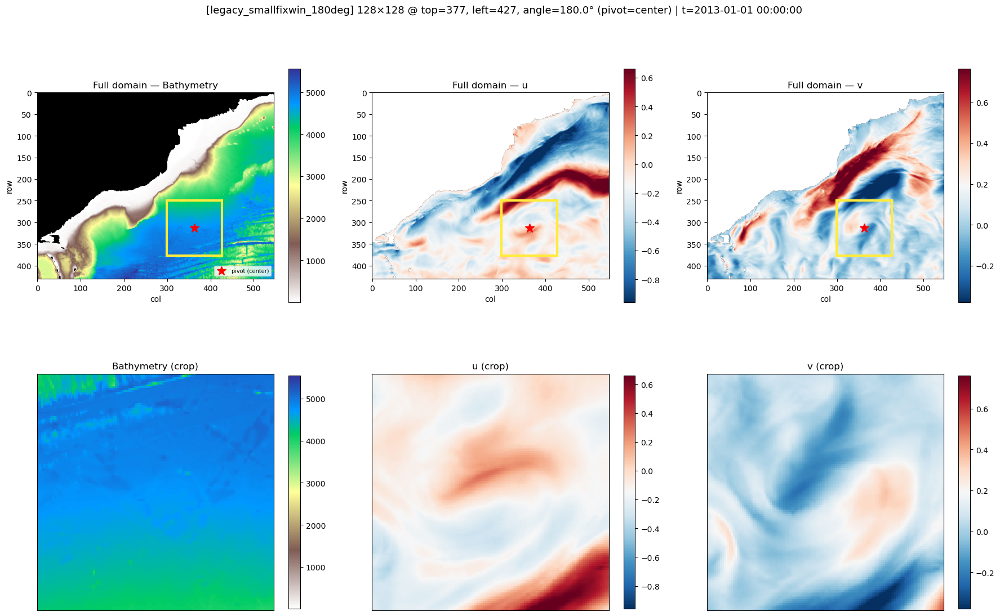

In [65]:
# legacy_smallfixwin_45deg — Legacy small (180°)
WINDOW = dict(
    export_key="legacy_smallfixwin_180deg",
    crop_height=128,
    crop_width=128,
    window_top=250,
    window_left=300,
    window_angle=180.0,
    rotation_pivot="center",
    pivot_col=None,
    pivot_row=None,
)

LEGACY_SMALL_SPEC = resolve_window("Legacy small (180°)", WINDOW)
print_window_info(LEGACY_SMALL_SPEC)
_ = visualize_window_on_domain(LEGACY_SMALL_SPEC)


## Size Effect

128×128 centered inside legacy large. **Run settings & helpers below first**, then cells 1→3.


In [67]:
# === Size Effect — settings & helpers ===
# Re-run this cell when you change section-specific settings below.
SECTION = "size_effect"

ZARR_PATH = os.getenv(
    "GUIANA_ZARR_PATH",
    "s3://oceangen-data/margem_equatorial_tensor.zarr",
)
VIZ_TIME_IDX = 0  # zarr time index for u/v snapshot

# Window outline on full-domain plots (high contrast on bathy / u / v)
WINDOW_EDGE_COLORS = {
    "legacy_largefixwin": "#FF6600",           # orange — large window
    "legacy_smallfixwin_in_large": "#00E5FF",  # cyan — small window
}
WINDOW_EDGE_WIDTH = 3

MAGIC_ANCHOR_TOP = int(EXPORT_ROW_SLICE[0])
MAGIC_ANCHOR_LEFT = int(EXPORT_COL_SLICE[0])
MAGIC_HEIGHT = int(EXPORT_ROW_SLICE[1] - EXPORT_ROW_SLICE[0])
MAGIC_WIDTH = int(EXPORT_COL_SLICE[1] - EXPORT_COL_SLICE[0])
MAGIC_CENTER_COL = MAGIC_ANCHOR_LEFT + (MAGIC_WIDTH - 1) / 2.0
MAGIC_CENTER_ROW = MAGIC_ANCHOR_TOP + (MAGIC_HEIGHT - 1) / 2.0
MAGIC_PIVOT_LEFT = MAGIC_ANCHOR_LEFT
MAGIC_PIVOT_BOTTOM_ROW = MAGIC_ANCHOR_TOP + MAGIC_HEIGHT - 1

print(
    f"Magic reference: top-left=({MAGIC_ANCHOR_TOP}, {MAGIC_ANCHOR_LEFT}), "
    f"center=({MAGIC_CENTER_COL:.1f}, {MAGIC_CENTER_ROW:.1f}), "
    f"size={MAGIC_HEIGHT}×{MAGIC_WIDTH}"
)


def top_left_from_center_pivot(
    pivot_col: float,
    pivot_row: float,
    height: int,
    width: int,
    angle_deg: float,
) -> tuple[int, int]:
    angle = np.deg2rad(float(angle_deg))
    sin_a, cos_a = float(np.sin(angle)), float(np.cos(angle))
    col_c = (int(width) - 1) / 2.0
    row_c = (int(height) - 1) / 2.0
    left = pivot_col - col_c * cos_a + row_c * sin_a
    top = pivot_row - col_c * sin_a - row_c * cos_a
    return int(round(top)), int(round(left))


def top_left_from_bottom_left_pivot(
    pivot_col: float,
    pivot_row: float,
    height: int,
    width: int,
    angle_deg: float,
) -> tuple[int, int]:
    angle = np.deg2rad(float(angle_deg))
    sin_a, cos_a = float(np.sin(angle)), float(np.cos(angle))
    h_span = max(int(height) - 1, 0)
    left = int(round(pivot_col + h_span * sin_a))
    top = int(round(pivot_row - h_span * cos_a))
    return top, left


def resolve_window(name: str, cfg: dict) -> dict:
    """Build export spec from editable WINDOW dict.

    cfg keys: crop_height, crop_width, window_angle, rotation_pivot,
              window_top, window_left, pivot_col, pivot_row (optional)
    rotation_pivot: "top_left" | "center" | "bottom_left"
    """
    h = int(cfg["crop_height"])
    w = int(cfg["crop_width"])
    ang = float(cfg["window_angle"])
    pivot_mode = str(cfg.get("rotation_pivot", "top_left"))

    pivot_col = cfg.get("pivot_col")
    pivot_row = cfg.get("pivot_row")
    win_top = cfg.get("window_top")
    win_left = cfg.get("window_left")

    if pivot_mode == "center":
        if pivot_col is None or pivot_row is None:
            if win_top is None or win_left is None:
                raise ValueError(f"{name}: center pivot needs pivot_col/pivot_row or window_top/window_left")
            pivot_col = float(win_left) + (w - 1) / 2.0
            pivot_row = float(win_top) + (h - 1) / 2.0
        top, left = top_left_from_center_pivot(float(pivot_col), float(pivot_row), h, w, ang)
    elif pivot_mode == "bottom_left":
        if pivot_col is None or pivot_row is None:
            if win_top is None or win_left is None:
                raise ValueError(f"{name}: bottom_left pivot needs pivot_col/pivot_row or window_top/window_left")
            pivot_col = float(win_left) + (h - 1) * np.sin(np.deg2rad(ang))
            pivot_row = float(win_top) + (h - 1) * np.cos(np.deg2rad(ang))
        top, left = top_left_from_bottom_left_pivot(float(pivot_col), float(pivot_row), h, w, ang)
    elif pivot_mode == "top_left":
        if win_top is None or win_left is None:
            raise ValueError(f"{name}: top_left pivot needs window_top and window_left")
        top, left = int(win_top), int(win_left)
        if pivot_col is None:
            pivot_col = left + (w - 1) / 2.0
        if pivot_row is None:
            pivot_row = top + (h - 1) / 2.0
    else:
        raise ValueError(f"Unknown rotation_pivot={pivot_mode!r}")

    center_col = left + (w - 1) / 2.0 * np.cos(np.deg2rad(ang)) - (h - 1) / 2.0 * np.sin(np.deg2rad(ang))
    center_row = top + (w - 1) / 2.0 * np.sin(np.deg2rad(ang)) + (h - 1) / 2.0 * np.cos(np.deg2rad(ang))

    export_key = str(cfg.get("export_key") or name)
    return {
        "name": name,
        "export_key": export_key,
        "crop_height": h,
        "crop_width": w,
        "window_top": int(top),
        "window_left": int(left),
        "window_angle": ang,
        "rotation_pivot": pivot_mode,
        "pivot_col": float(pivot_col) if pivot_col is not None else None,
        "pivot_row": float(pivot_row) if pivot_row is not None else None,
        "center_col": float(center_col),
        "center_row": float(center_row),
    }


def _extract_frame_channels(frame_arr, ch_names):
    arr = np.asarray(frame_arr)
    if arr.ndim == 5:
        arr = arr[0]
    if arr.ndim == 4 and arr.shape[0] == 1:
        arr = arr[0]
    idx = {n: i for i, n in enumerate(ch_names)}
    return {name: np.asarray(arr[idx[name]]) for name in ("bathymetry", "u", "v")}


def load_domain_fields(time_idx: int = VIZ_TIME_IDX):
    zgroup = zarr.open_group(ZARR_PATH, mode="r")
    ch_names = [c.decode() if isinstance(c, bytes) else str(c) for c in zgroup["channel"][:]]
    fields = _extract_frame_channels(zgroup["ocean_tensor"][int(time_idx)], ch_names)
    t_str = str(pd.to_datetime(zgroup["time"][int(time_idx)]))
    return fields, t_str, ch_names


def build_window_crop(crop_height, crop_width, window_top, window_left, window_angle):
    if float(window_angle) == 0.0:
        return FixedCrop(size=(crop_height, crop_width), top=window_top, left=window_left)
    return RotatedFixedCrop(
        size=(crop_height, crop_width),
        top=window_top,
        left=window_left,
        angle_deg=float(window_angle),
    )


def print_window_info(spec: dict):
    export_key = spec.get("export_key", spec["name"])
    rows = [
        ("export_key", export_key),
        ("data_dir", f"Magic_window/data/{export_key}"),
        ("train_prefix", f"Magic_window/data/{export_key}/sample_13_22_train_uv_dt360"),
        ("val_prefix", f"Magic_window/data/{export_key}/sample_13_22_val_uv_dt360"),
        ("test_prefix", f"Magic_window/data/{export_key}/sample_23_uv_dt360"),
        ("crop_height", spec["crop_height"]),
        ("crop_width", spec["crop_width"]),
        ("window_top", spec["window_top"]),
        ("window_left", spec["window_left"]),
        ("window_angle", spec["window_angle"]),
        ("rotation_pivot", spec["rotation_pivot"]),
        ("pivot_col", spec.get("pivot_col")),
        ("pivot_row", spec.get("pivot_row")),
        ("center_col", round(spec["center_col"], 2)),
        ("center_row", round(spec["center_row"], 2)),
        (
            "export_window.npy",
            f"[{spec['window_top']}, {spec['window_left']}, {spec['crop_height']}, "
            f"{spec['crop_width']}, {spec['window_angle']}]",
        ),
    ]
    info = pd.DataFrame(rows, columns=["field", "value"])
    try:
        display(info.style.hide(axis="index"))
    except Exception:
        print(info.to_string(index=False))
    print("Copy for export notebook:")
    for key in ("CROP_HEIGHT", "CROP_WIDTH", "WINDOW_TOP", "WINDOW_LEFT", "WINDOW_ANGLE"):
        src = key.replace("CROP_", "crop_").replace("WINDOW_", "window_").lower()
        val = spec[src]
        print(f"  {key} = {val!r}")
    if spec["window_top"] < 0 or spec["window_left"] < 0:
        print("WARNING: window_top or window_left < 0 — RotatedFixedCrop will reject this geometry.")
    return spec


def _window_edge_style(spec: dict) -> tuple[str, float]:
    key = spec.get("export_key", "")
    color = WINDOW_EDGE_COLORS.get(key, "#FFEB3B")  # bright yellow fallback
    return color, WINDOW_EDGE_WIDTH


def _add_window_outline(ax, spec, edgecolor=None, linewidth=None, label=None):
    if edgecolor is None or linewidth is None:
        default_color, default_width = _window_edge_style(spec)
        edgecolor = default_color if edgecolor is None else edgecolor
        linewidth = default_width if linewidth is None else linewidth
    top, left = spec["window_top"], spec["window_left"]
    h, w, ang = spec["crop_height"], spec["crop_width"], spec["window_angle"]
    if float(ang) == 0.0:
        ax.add_patch(Rectangle((left, top), w, h, fill=False, edgecolor=edgecolor, linewidth=linewidth, label=label))
    else:
        corners = rotated_window_corners(top, left, h, ang, w)
        ax.add_patch(Polygon(corners, fill=False, edgecolor=edgecolor, linewidth=linewidth, label=label))
    pc, pr = spec.get("pivot_col"), spec.get("pivot_row")
    if spec["rotation_pivot"] == "center" and pc is not None and pr is not None:
        ax.plot(pc, pr, "r*", ms=12, label="pivot (center)")
    elif spec["rotation_pivot"] == "bottom_left" and pc is not None and pr is not None:
        ax.plot(pc, pr, "r*", ms=12, label="pivot (BL)")


def _percentile_vlim(field, lo=2, hi=98):
    valid = field[np.isfinite(field)]
    if valid.size == 0:
        return None, None
    return float(np.percentile(valid, lo)), float(np.percentile(valid, hi))


def visualize_window_on_domain(spec: dict, time_idx: int = VIZ_TIME_IDX, show_crops: bool = True):
    fields, t_str, _ = load_domain_fields(time_idx)
    bathy, u, v = fields["bathymetry"], fields["u"], fields["v"]
    b_valid = bathy[np.isfinite(bathy) & (bathy != 0)]
    b_vmin = float(b_valid.min()) if b_valid.size else None
    b_vmax = float(b_valid.max()) if b_valid.size else None
    u_vmin, u_vmax = _percentile_vlim(u)
    v_vmin, v_vmax = _percentile_vlim(v)

    nrows = 2 if show_crops else 1
    fig, axes = plt.subplots(nrows, 3, figsize=(18, 6 * nrows))
    if nrows == 1:
        axes = np.expand_dims(axes, 0)

    panels = [
        (bathy, "Bathymetry", bathymetry_cmap(), b_vmin, b_vmax),
        (u, "u", "RdBu_r", u_vmin, u_vmax),
        (v, "v", "RdBu_r", v_vmin, v_vmax),
    ]
    for ax, (field, label, cmap, vmin, vmax) in zip(axes[0], panels):
        masked = mask_bathymetry_land(field) if label == "Bathymetry" else field
        im = ax.imshow(masked, cmap=cmap, vmin=vmin, vmax=vmax, origin="upper")
        _add_window_outline(ax, spec)
        ax.set_title(f"Full domain — {label}")
        ax.set_xlabel("col")
        ax.set_ylabel("row")
        fig.colorbar(im, ax=ax, shrink=0.7)
    axes[0, 0].legend(loc="lower right", fontsize=7)

    if show_crops:
        stack = torch.tensor(np.stack([u, v, bathy], axis=0), dtype=torch.float32)
        crop = build_window_crop(spec["crop_height"], spec["crop_width"], spec["window_top"], spec["window_left"], spec["window_angle"])
        cropped = crop(stack).numpy()
        for ax, (field, title, cmap, vmin, vmax) in zip(
            axes[1],
            [
                (cropped[2], "Bathymetry (crop)", bathymetry_cmap(), b_vmin, b_vmax),
                (cropped[0], "u (crop)", "RdBu_r", u_vmin, u_vmax),
                (cropped[1], "v (crop)", "RdBu_r", v_vmin, v_vmax),
            ],
        ):
            masked = mask_bathymetry_land(field) if title.startswith("Bathymetry") else field
            im = ax.imshow(masked, cmap=cmap, vmin=vmin, vmax=vmax, origin="upper")
            ax.set_title(title)
            ax.set_xticks([])
            ax.set_yticks([])
            fig.colorbar(im, ax=ax, shrink=0.7)

    fig.suptitle(
        f"[{spec.get('export_key', spec['name'])}] {spec['crop_height']}×{spec['crop_width']} @ "
        f"top={spec['window_top']}, left={spec['window_left']}, angle={spec['window_angle']}° "
        f"(pivot={spec['rotation_pivot']}) | t={t_str}",
        fontsize=13,
    )
    plt.tight_layout()
    plt.show()



try:
    _probe, _t0, _ = load_domain_fields(VIZ_TIME_IDX)
    print(f"Loaded zarr fields @ time index {VIZ_TIME_IDX}: {_t0}")
    print(f"Grid shape (rows×cols): {_probe['bathymetry'].shape}")
except Exception as exc:
    print(f"Could not preload zarr (set GUIANA_ZARR_PATH): {exc}")

Magic reference: top-left=(226, 85), center=(148.5, 289.5), size=128×128
Loaded zarr fields @ time index 0: 2013-01-01 00:00:00
Grid shape (rows×cols): (431, 547)


In [68]:
# --- 1) Derive small window at center of legacy large (same angle) ---
LARGE_WINDOW = dict(
    export_key="legacy_largefixwin",
    crop_height=128,
    crop_width=384,
    window_top=None,
    window_left=None,
    window_angle=-35.0,
    rotation_pivot="center",
    pivot_col=303.2897,
    pivot_row=262.1763,
)
LARGE_REF_SPEC = resolve_window("Legacy large (−35°)", LARGE_WINDOW)

WINDOW = dict(
    export_key="legacy_smallfixwin_in_large",
    crop_height=128,
    crop_width=128,
    window_top=None,
    window_left=None,
    window_angle=LARGE_REF_SPEC["window_angle"],
    rotation_pivot="center",
    pivot_col=LARGE_REF_SPEC["center_col"],
    pivot_row=LARGE_REF_SPEC["center_row"],
)

SMALL_IN_LARGE_SPEC = resolve_window("Small in large", WINDOW)

print("Size-effect geometry ready:")
print(f"  large  [{LARGE_REF_SPEC['export_key']}]  {LARGE_REF_SPEC['crop_height']}×{LARGE_REF_SPEC['crop_width']} "
      f"@ top={LARGE_REF_SPEC['window_top']}, left={LARGE_REF_SPEC['window_left']}, angle={LARGE_REF_SPEC['window_angle']}°")
print(f"  small  [{SMALL_IN_LARGE_SPEC['export_key']}]  {SMALL_IN_LARGE_SPEC['crop_height']}×{SMALL_IN_LARGE_SPEC['crop_width']} "
      f"@ top={SMALL_IN_LARGE_SPEC['window_top']}, left={SMALL_IN_LARGE_SPEC['window_left']}, angle={SMALL_IN_LARGE_SPEC['window_angle']}°")
print(f"  centers match: col Δ={abs(SMALL_IN_LARGE_SPEC['center_col'] - LARGE_REF_SPEC['center_col']):.3f}, "
      f"row Δ={abs(SMALL_IN_LARGE_SPEC['center_row'] - LARGE_REF_SPEC['center_row']):.3f}")


Size-effect geometry ready:
  large  [legacy_largefixwin]  128×384 @ top=320, left=110, angle=-35.0°
  small  [legacy_smallfixwin_in_large]  128×128 @ top=247, left=215, angle=-35.0°
  centers match: col Δ=0.149, row Δ=0.418


field,value
export_key,legacy_largefixwin
data_prefix,Magic_window/data/sample_13_22_legacy_largefixwin_uv_dt360
crop_height,128
crop_width,384
window_top,320
window_left,110
window_angle,-35.000000
rotation_pivot,center
pivot_col,303.289700
pivot_row,262.176300


Copy for export notebook:
  CROP_HEIGHT = 128
  CROP_WIDTH = 384
  WINDOW_TOP = 320
  WINDOW_LEFT = 110
  WINDOW_ANGLE = -35.0


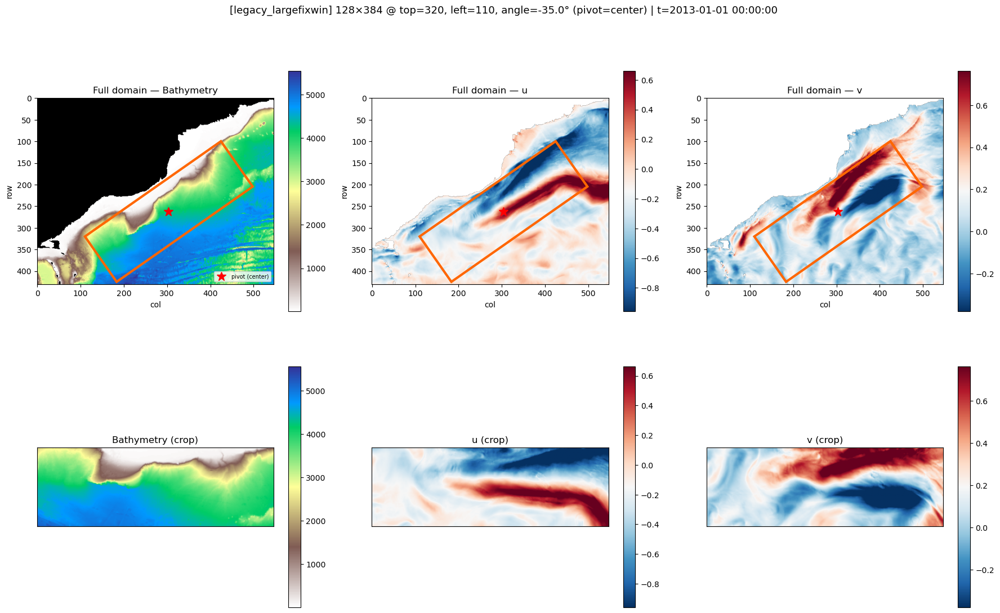

In [69]:
# --- 2) Export preview: legacy_largefixwin (large window) ---
print_window_info(LARGE_REF_SPEC)
_ = visualize_window_on_domain(LARGE_REF_SPEC)

field,value
export_key,legacy_smallfixwin_in_large
data_prefix,Magic_window/data/sample_13_22_legacy_smallfixwin_in_large_uv_dt360
crop_height,128
crop_width,128
window_top,247
window_left,215
window_angle,-35.000000
rotation_pivot,center
pivot_col,303.289720
pivot_row,262.176267


Copy for export notebook:
  CROP_HEIGHT = 128
  CROP_WIDTH = 128
  WINDOW_TOP = 247
  WINDOW_LEFT = 215
  WINDOW_ANGLE = -35.0


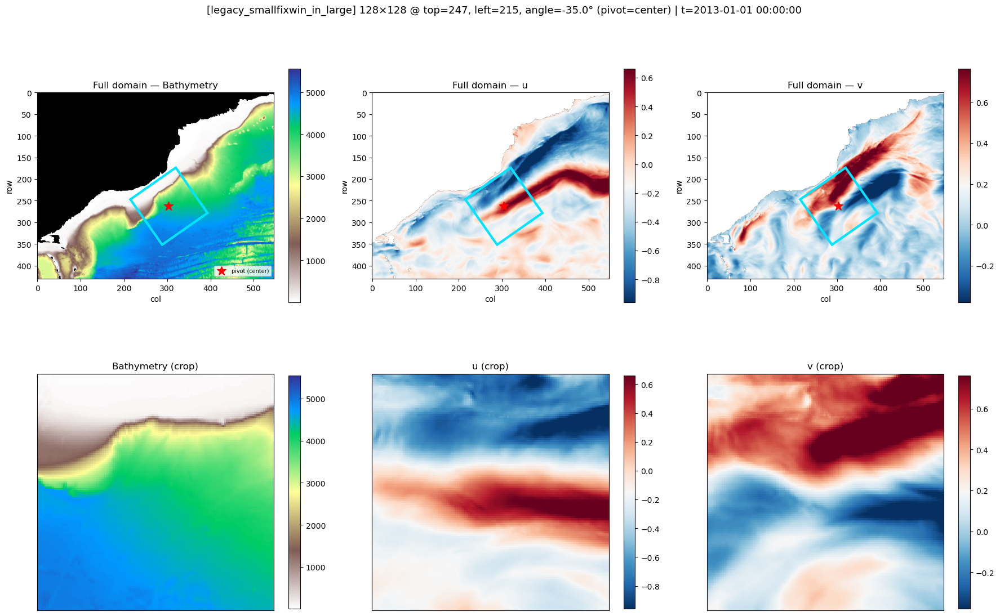

In [70]:
# --- 3) Export preview: legacy_smallfixwin_in_large (small, centered in large) ---
print_window_info(SMALL_IN_LARGE_SPEC)
_ = visualize_window_on_domain(SMALL_IN_LARGE_SPEC)

## Overview — all windows in this notebook

Bathymetry map with every window from the section cells above. **Export keys** and display names are listed in the legend on the **right** of the figure.

Lookup: `NOTEBOOK_WINDOWS_BY_KEY["magicwin_high_land"]` or `NOTEBOOK_WINDOWS_BY_NAME["High land"]`.

Run **Setup** (cells 1–2) first.

In [ ]:
%matplotlib inline
import re

# === Overview — all windows defined in this notebook ===
# Run setup (cells 1–2) first, then this cell.

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)

from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle, Polygon

if "rotated_window_corners" not in globals():
    from src.data.useful_transforms import rotated_window_corners

if "EXPORT_ROW_SLICE" not in globals() or "EXPORT_COL_SLICE" not in globals():
    raise RuntimeError("Run setup cell 1 first (loads EXPORT_ROW_SLICE / EXPORT_COL_SLICE).")

VIZ_TIME_IDX = globals().get("VIZ_TIME_IDX", 0)
ZARR_PATH = globals().get(
    "ZARR_PATH",
    os.getenv("GUIANA_ZARR_PATH", "s3://oceangen-data/margem_equatorial_tensor.zarr"),
)

_magic_top = int(EXPORT_ROW_SLICE[0])
_magic_left = int(EXPORT_COL_SLICE[0])

NOTEBOOK_WINDOW_COLORS = [
    "#00E5FF", "#FF6600", "#76FF03", "#E040FB", "#FFD600",
    "#FF5252", "#00BCD4", "#9C27B0", "#FF4081", "#00E676",
    "#795548", "#607D8B", "#3F51B5", "#009688",
]
OVERVIEW_EDGE_WIDTH = 3.0

# (export_key, display_name, section, cfg) — must match section cells above
NOTEBOOK_WINDOW_CATALOG = [
    (
        "magicwin_reference",
        "Magic window (reference)",
        "Effect of lands",
        dict(
            crop_height=128, crop_width=128,
            window_top=_magic_top, window_left=_magic_left,
            window_angle=0.0, rotation_pivot="top_left",
        ),
    ),
    (
        "magicwin_high_land",
        "High land",
        "Effect of lands",
        dict(
            crop_height=128, crop_width=128,
            window_top=186, window_left=85,
            window_angle=0.0, rotation_pivot="top_left",
        ),
    ),
    (
        "magicwin_open_ocean",
        "Open ocean (no land)",
        "Effect of lands",
        dict(
            crop_height=128, crop_width=128,
            window_top=300, window_left=85,
            window_angle=0.0, rotation_pivot="top_left",
        ),
    ),
    (
        "magicwin_bathy_mid",
        "Bathymetry — mid domain",
        "Bathymetry Effect",
        dict(
            crop_height=128, crop_width=128,
            window_top=300, window_left=245,
            window_angle=0.0, rotation_pivot="top_left",
        ),
    ),
    (
        "magicwin_bathy_east",
        "Bathymetry — east",
        "Bathymetry Effect",
        dict(
            crop_height=128, crop_width=128,
            window_top=300, window_left=400,
            window_angle=0.0, rotation_pivot="top_left",
        ),
    ),
    (
        "magicwin_bathy_northeast",
        "Bathymetry — northeast",
        "Bathymetry Effect",
        dict(
            crop_height=128, crop_width=128,
            window_top=100, window_left=350,
            window_angle=0.0, rotation_pivot="top_left",
        ),
    ),
    (
        "legacy_smallfixwin_0deg",
        "Legacy small (0°)",
        "Rotation Effect",
        dict(
            crop_height=128, crop_width=128,
            window_top=250, window_left=300,
            window_angle=0.0, rotation_pivot="center",
        ),
    ),
    (
        "legacy_smallfixwin_23deg",
        "Legacy small (23°)",
        "Rotation Effect",
        dict(
            crop_height=128, crop_width=128,
            window_top=250, window_left=300,
            window_angle=23.0, rotation_pivot="center",
        ),
    ),
    (
        "legacy_smallfixwin_68deg",
        "Legacy small (68°)",
        "Rotation Effect",
        dict(
            crop_height=128, crop_width=128,
            window_top=250, window_left=300,
            window_angle=68.0, rotation_pivot="center",
        ),
    ),
    (
        "legacy_smallfixwin_45deg",
        "Legacy small (45°)",
        "Rotation Effect",
        dict(
            crop_height=128, crop_width=128,
            window_top=250, window_left=300,
            window_angle=45.0, rotation_pivot="center",
        ),
    ),
    (
        "legacy_smallfixwin_90deg",
        "Legacy small (90°)",
        "Rotation Effect",
        dict(
            crop_height=128, crop_width=128,
            window_top=250, window_left=300,
            window_angle=90.0, rotation_pivot="center",
        ),
    ),
    (
        "legacy_smallfixwin_135deg",
        "Legacy small (135°)",
        "Rotation Effect",
        dict(
            crop_height=128, crop_width=128,
            window_top=250, window_left=300,
            window_angle=135.0, rotation_pivot="center",
        ),
    ),
    (
        "legacy_smallfixwin_180deg",
        "Legacy small (180°)",
        "Rotation Effect",
        dict(
            crop_height=128, crop_width=128,
            window_top=250, window_left=300,
            window_angle=180.0, rotation_pivot="center",
        ),
    ),
    (
        "legacy_largefixwin",
        "Legacy large (−35°)",
        "Size Effect",
        dict(
            crop_height=128, crop_width=384,
            window_top=None, window_left=None,
            window_angle=-35.0, rotation_pivot="center",
            pivot_col=303.2897, pivot_row=262.1763,
        ),
    ),
]


def _ensure_resolve_window():
    if "resolve_window" in globals():
        return globals()["resolve_window"]

    def top_left_from_center_pivot(pivot_col, pivot_row, height, width, angle_deg):
        angle = np.deg2rad(float(angle_deg))
        sin_a, cos_a = float(np.sin(angle)), float(np.cos(angle))
        col_c = (int(width) - 1) / 2.0
        row_c = (int(height) - 1) / 2.0
        left = pivot_col - col_c * cos_a + row_c * sin_a
        top = pivot_row - col_c * sin_a - row_c * cos_a
        return int(round(top)), int(round(left))

    def resolve_window(name, cfg):
        h = int(cfg["crop_height"])
        w = int(cfg["crop_width"])
        ang = float(cfg["window_angle"])
        pivot_mode = str(cfg.get("rotation_pivot", "top_left"))
        pivot_col = cfg.get("pivot_col")
        pivot_row = cfg.get("pivot_row")
        win_top = cfg.get("window_top")
        win_left = cfg.get("window_left")
        if pivot_mode == "center":
            if pivot_col is None or pivot_row is None:
                if win_top is None or win_left is None:
                    raise ValueError(f"{name}: center pivot needs pivot_col/pivot_row or window_top/window_left")
                pivot_col = float(win_left) + (w - 1) / 2.0
                pivot_row = float(win_top) + (h - 1) / 2.0
            top, left = top_left_from_center_pivot(float(pivot_col), float(pivot_row), h, w, ang)
        elif pivot_mode == "top_left":
            if win_top is None or win_left is None:
                raise ValueError(f"{name}: top_left pivot needs window_top and window_left")
            top, left = int(win_top), int(win_left)
            if pivot_col is None:
                pivot_col = left + (w - 1) / 2.0
            if pivot_row is None:
                pivot_row = top + (h - 1) / 2.0
        else:
            raise ValueError(f"Unknown rotation_pivot={pivot_mode!r}")
        center_col = left + (w - 1) / 2.0 * np.cos(np.deg2rad(ang)) - (h - 1) / 2.0 * np.sin(np.deg2rad(ang))
        center_row = top + (w - 1) / 2.0 * np.sin(np.deg2rad(ang)) + (h - 1) / 2.0 * np.cos(np.deg2rad(ang))
        export_key = str(cfg.get("export_key") or name)
        return {
            "name": name,
            "export_key": export_key,
            "crop_height": h, "crop_width": w,
            "window_top": int(top), "window_left": int(left),
            "window_angle": ang, "rotation_pivot": pivot_mode,
            "pivot_col": float(pivot_col) if pivot_col is not None else None,
            "pivot_row": float(pivot_row) if pivot_row is not None else None,
            "center_col": float(center_col), "center_row": float(center_row),
        }

    return resolve_window


def build_notebook_window_specs():
    resolve_window = _ensure_resolve_window()
    specs = []
    large_spec = None

    for i, (export_key, display_name, section, cfg) in enumerate(NOTEBOOK_WINDOW_CATALOG):
        cfg = dict(cfg)
        cfg["export_key"] = export_key
        spec = resolve_window(display_name, cfg)
        spec["display_name"] = display_name
        spec["section"] = section
        spec["color"] = NOTEBOOK_WINDOW_COLORS[i % len(NOTEBOOK_WINDOW_COLORS)]
        spec["data_dir"] = f"Magic_window/data/{export_key}"
        spec["train_prefix"] = f"Magic_window/data/{export_key}/sample_13_22_train_uv_dt360"
        spec["val_prefix"] = f"Magic_window/data/{export_key}/sample_13_22_val_uv_dt360"
        spec["test_prefix"] = f"Magic_window/data/{export_key}/sample_23_uv_dt360"
        specs.append(spec)
        if export_key == "legacy_largefixwin":
            large_spec = spec

    small_cfg = dict(
        export_key="legacy_smallfixwin_in_large",
        crop_height=128, crop_width=128,
        window_top=None, window_left=None,
        window_angle=large_spec["window_angle"],
        rotation_pivot="center",
        pivot_col=large_spec["center_col"],
        pivot_row=large_spec["center_row"],
    )
    small_spec = resolve_window("Small in large", small_cfg)
    small_spec["display_name"] = "Small in large"
    small_spec["section"] = "Size Effect"
    small_spec["color"] = NOTEBOOK_WINDOW_COLORS[len(specs) % len(NOTEBOOK_WINDOW_COLORS)]
    small_spec["data_dir"] = "Magic_window/data/legacy_smallfixwin_in_large"
    small_spec["train_prefix"] = "Magic_window/data/legacy_smallfixwin_in_large/sample_13_22_train_uv_dt360"
    small_spec["val_prefix"] = "Magic_window/data/legacy_smallfixwin_in_large/sample_13_22_val_uv_dt360"
    small_spec["test_prefix"] = "Magic_window/data/legacy_smallfixwin_in_large/sample_23_uv_dt360"
    specs.append(small_spec)
    return specs


def _overview_add_window(ax, spec, edgecolor, linewidth=OVERVIEW_EDGE_WIDTH):
    top, left = spec["window_top"], spec["window_left"]
    h, w, ang = spec["crop_height"], spec["crop_width"], spec["window_angle"]
    if float(ang) == 0.0:
        ax.add_patch(Rectangle((left, top), w, h, fill=False, edgecolor=edgecolor, linewidth=linewidth))
    else:
        corners = rotated_window_corners(top, left, h, ang, w)
        ax.add_patch(Polygon(corners, fill=False, edgecolor=edgecolor, linewidth=linewidth))


def _overview_legend(ax_note, specs):
    ax_note.axis("off")
    handles = []
    for spec in specs:
        label = (
            f"{spec['export_key']}\n"
            f"{spec['display_name']}  ·  {spec['section']}\n"
            f"{spec['crop_height']}×{spec['crop_width']} @ {spec['window_angle']:.0f}°  "
            f"(top={spec['window_top']}, left={spec['window_left']})"
        )
        handles.append(Line2D([0], [0], color=spec["color"], lw=4, label=label))
    ax_note.legend(
        handles=handles,
        loc="upper left",
        frameon=True,
        title="Export keys (for data export)",
        fontsize=8,
        title_fontsize=9,
        framealpha=1.0,
        facecolor="#fafafa",
        edgecolor="#444444",
        borderpad=0.8,
        labelspacing=1.1,
        handlelength=2.5,
    )


def plot_all_notebook_windows(time_idx: int = VIZ_TIME_IDX):
    specs = build_notebook_window_specs()

    if "load_domain_fields" in globals():
        fields, t_str, _ = load_domain_fields(time_idx)
    else:
        zgroup = zarr.open_group(ZARR_PATH, mode="r")
        ch_names = [c.decode() if isinstance(c, bytes) else str(c) for c in zgroup["channel"][:]]
        arr = np.asarray(zgroup["ocean_tensor"][int(time_idx)])
        if arr.ndim == 5:
            arr = arr[0]
        if arr.ndim == 4 and arr.shape[0] == 1:
            arr = arr[0]
        idx = {n: i for i, n in enumerate(ch_names)}
        fields = {name: np.asarray(arr[idx[name]]) for name in ("bathymetry", "u", "v")}
        t_str = str(pd.to_datetime(zgroup["time"][int(time_idx)]))

    bathy = fields["bathymetry"]
    b_valid = bathy[np.isfinite(bathy) & (bathy != 0)]
    b_vmin = float(b_valid.min()) if b_valid.size else None
    b_vmax = float(b_valid.max()) if b_valid.size else None

    fig = plt.figure(figsize=(16, 9), constrained_layout=True)
    gs = fig.add_gridspec(1, 2, width_ratios=[3.2, 1.8], wspace=0.04)
    ax_map = fig.add_subplot(gs[0, 0])
    ax_note = fig.add_subplot(gs[0, 1])

    masked = mask_bathymetry_land(bathy)
    im = ax_map.imshow(masked, cmap=bathymetry_cmap(), vmin=b_vmin, vmax=b_vmax, origin="upper")
    for spec in specs:
        _overview_add_window(ax_map, spec, edgecolor=spec["color"])
    ax_map.set_title("Full domain — Bathymetry")
    ax_map.set_xlabel("col")
    ax_map.set_ylabel("row")
    fig.colorbar(im, ax=ax_map, shrink=0.85, pad=0.02)

    _overview_legend(ax_note, specs)

    fig.suptitle(
        f"All export windows ({len(specs)}) | t={t_str}",
        fontsize=13,
        y=0.98,
    )
    return fig, specs


ALL_NOTEBOOK_SPECS = build_notebook_window_specs()

print("Export windows (by section):")
print("-" * 78)
current_section = None
for s in ALL_NOTEBOOK_SPECS:
    if s["section"] != current_section:
        current_section = s["section"]
        print(f"\n[{current_section}]")
    print(
        f"  {s['export_key']:32s}  {s['display_name']}\n"
        f"    {s['crop_height']}×{s['crop_width']} @ {s['window_angle']:.0f}°  "
        f"top={s['window_top']} left={s['window_left']}"
    )
print("-" * 78)

NOTEBOOK_WINDOWS_BY_KEY = {s["export_key"]: s for s in ALL_NOTEBOOK_SPECS}
NOTEBOOK_WINDOWS_BY_NAME = {s["display_name"]: s for s in ALL_NOTEBOOK_SPECS}

overview_fig, _ = plot_all_notebook_windows()
display(overview_fig)
plt.show()
overview_fig
